# Bibliothèques + configuration GPU

In [1]:
# Bibliothèques utilisées dans ce notebook
# ------------------------------------------------------------
import re
import pandas as pd
from collections import Counter
import torch.nn as nn
import numpy as np
import time
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from sklearn.metrics import accuracy_score, f1_score
from copy import deepcopy

# Configuration PyTorch
# ------------------------------------------------------------
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

assert torch.cuda.is_available(), "GPU CUDA indisponible !"
device = torch.device("cuda:0")

print(f"GPU : {torch.cuda.get_device_name(0)}")

GPU : Quadro RTX 5000


# Import et assemblage des données

In [4]:
# Chargement du dataset préparé et de son découpage
# ------------------------------------------------------------
df = pd.read_csv("../csv/split_text_data.csv")

# Séparation des ensembles
# ------------------------------------------------------------
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

# Texte naturel traduit pour le Deep Learning
X_train_text = train_df["texte_traduit"]
X_val_text = val_df["texte_traduit"]

print("Train :", len(train_df))
print("Validation :", len(val_df))
print("Test :", len(test_df))
print("Nombre de classes :", df["prdtypecode"].nunique())
print("Nombre de textes manquants :", df["texte_traduit"].isna().sum())

Train : 66802
Validation : 8351
Test : 8350
Nombre de classes : 27
Nombre de textes manquants : 0


# Preprocessing / Feature Engineering pour DL

## Tokenisation des textes

In [5]:

# Reconnaissance des mots, références et ponctuations
pattern = re.compile(r"\w+(?:[-'’./]\w+)*|[^\w\s]")

def tokenizer(texte):
    return pattern.findall(texte.lower())

frequences = Counter()

for texte in X_train_text:
    frequences.update(tokenizer(texte))

print("Tokens distincts :", len(frequences))
print("Tokens présents une seule fois :", sum(freq == 1 for freq in frequences.values()))


Tokens distincts : 189675
Tokens présents une seule fois : 105473


## Construction du vocabulaire

In [6]:
min_freq = 2 # On choisi arbitrairement de ne garder que les tokens présents au moins 2 fois dans le vocabulaire car il y a 55% de tokens uniques

# Tokens spéciaux
vocab = {"<PAD>": 0, # Token de padding pour les séquences tronquées
         "<UNK>": 1} # Token inconnu pour les tokens non présents dans le vocabulaire

# Ajout des tokens suffisamment fréquents
for mot, freq in frequences.most_common():
    if freq >= min_freq:
        vocab[mot] = len(vocab)

print("Taille du vocabulaire :", len(vocab))

Taille du vocabulaire : 84204


## Conversion des textes en identifiants

In [7]:

def encoder_texte(texte):
    tokens = tokenizer(texte)
    return [vocab.get(token, vocab["<UNK>"]) for token in tokens]

# Encodage numérique de tous les textes
# ------------------------------------------------------------

sequences_train = [encoder_texte(texte) for texte in X_train_text]
sequences_val = [encoder_texte(texte) for texte in X_val_text]

print("Séquences d'entraînement :", len(sequences_train))
print("Séquences de validation :", len(sequences_val))

print("\nExemple sur le premier produit :")
print("Texte :", X_train_text.iloc[0])
print("Tokens :", tokenizer(X_train_text.iloc[0]))
print("Première séquence :")
print(sequences_train[0][:30])
print("Nombre de tokens :", len(sequences_train[0]))




Séquences d'entraînement : 66802
Séquences de validation : 8351

Exemple sur le premier produit :
Texte : Olivia: Carnet personnalisé / 150 pages / Grille de points / Ca Din A5 / Design de roses
Tokens : ['olivia', ':', 'carnet', 'personnalisé', '/', '150', 'pages', '/', 'grille', 'de', 'points', '/', 'ca', 'din', 'a5', '/', 'design', 'de', 'roses']
Première séquence :
[24913, 3, 837, 3434, 25, 657, 686, 25, 3419, 2, 556, 25, 6306, 8081, 678, 25, 131, 2, 4898]
Nombre de tokens : 19


## Analyse des longueurs après tokenisation

In [8]:
longueurs_train = np.array([len(seq) for seq in sequences_train])

print("Longueur moyenne :", round(longueurs_train.mean(), 1))
print("Longueur médiane :", np.median(longueurs_train))
print("Longueur maximale :", longues_max := longueurs_train.max())

print("\nDistribution des longueurs :")
for percentile in [50, 75, 90, 95, 99]:
    valeur = np.percentile(longueurs_train, percentile)
    print(f"{percentile} % des textes ont au maximum {valeur:.0f} tokens")

print("\nSéquences vides :", (longueurs_train == 0).sum())


Longueur moyenne : 98.2
Longueur médiane : 52.0
Longueur maximale : 2238

Distribution des longueurs :
50 % des textes ont au maximum 52 tokens
75 % des textes ont au maximum 146 tokens
90 % des textes ont au maximum 241 tokens
95 % des textes ont au maximum 328 tokens
99 % des textes ont au maximum 562 tokens

Séquences vides : 0


## Préparation des séquences et des cibles

In [9]:

MAX_LEN = 512 # Conserve intégralement les textes jusqu'à 512 tokens, puis tronque le reste (entre 1 et 4% des textes seront tronqués)
BATCH_SIZE = 64

# Encodage des textes et troncature
sequences_train = [encoder_texte(texte)[:MAX_LEN] or [vocab["<UNK>"]] for texte in X_train_text]
sequences_val = [encoder_texte(texte)[:MAX_LEN] or [vocab["<UNK>"]] for texte in X_val_text]

# Encodage des 27 classes en indices de 0 à 26 tout en gardant un dictionnaire de correspondance
classes = sorted(train_df["prdtypecode"].unique())

code_to_idx = {code: i for i, code in enumerate(classes)}
idx_to_code = {i: code for code, i in code_to_idx.items()}

y_train = train_df["prdtypecode"].map(code_to_idx).tolist()
y_val = val_df["prdtypecode"].map(code_to_idx).tolist()

print("Taille du vocabulaire :", len(vocab))
print("Nombre de classes :", len(classes))
print("Séquences train :", len(sequences_train))
print("Séquences validation :", len(sequences_val))
print("Longueur maximale :", MAX_LEN)


Taille du vocabulaire : 84204
Nombre de classes : 27
Séquences train : 66802
Séquences validation : 8351
Longueur maximale : 512


## Création de DataLoaders (padding dynamique)

Plutôt que de compléter systématiquement toutes les fiches jusqu'à 512 tokens, chaque batch sera complété uniquement jusqu'à la longueur de sa séquence la plus longue (avec un maximum de 512).

In [10]:

# Création du Dataset
# ------------------------------------------------------------
class TexteDataset(Dataset):

    def __init__(self, sequences, labels):
        self.sequences = sequences
        self.labels = labels

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.sequences[idx], dtype=torch.long),
            self.labels[idx]
        )


# Padding dynamique à chaque batch
# ------------------------------------------------------------
def collate_fn(batch):
    sequences, labels = zip(*batch)

    longueurs = torch.tensor(
        [len(seq) for seq in sequences],
        dtype=torch.long
    )

    X = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=vocab["<PAD>"]
    )

    y = torch.tensor(labels, dtype=torch.long)

    return X, longueurs, y


# Création des DataLoaders
# ------------------------------------------------------------
train_loader = DataLoader(
    TexteDataset(sequences_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    TexteDataset(sequences_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)

# Vérification d'un batch
X_batch, longueurs_batch, y_batch = next(iter(train_loader))

print("Dimensions X :", X_batch.shape)
print("Dimensions y :", y_batch.shape)


Dimensions X : torch.Size([64, 415])
Dimensions y : torch.Size([64])


# RNN (Recurrent Neural Network)

Réseau de neurones conçu pour traiter des données séquentielles, comme du texte, de l'audio ou des séries temporelles.

Sa particularité est de conserver un état caché qui transmet des informations d'une étape à la suivante.

## Architecture

In [11]:

class RNNClassifier(nn.Module):

    def __init__(self, vocab_size, nb_classes):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=128,
            padding_idx=0
        )

        self.rnn = nn.RNN(
            input_size=128,
            hidden_size=128,
            batch_first=True
        )

        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, nb_classes)

    def forward(self, X, longueurs):

        # Conversion des identifiants en embeddings
        X = self.embedding(X)

        # Exclusion des positions de padding du calcul récurrent
        X = pack_padded_sequence(
            X,
            longueurs.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # Récupération du dernier état caché
        _, hidden = self.rnn(X)

        # Classification
        X = self.dropout(hidden[-1])
        return self.fc(X)





## Initialisation du modèle

In [12]:
model = RNNClassifier(
    vocab_size=len(vocab),
    nb_classes=len(classes)
).to(device)

print("Modèle sur :", next(model.parameters()).device)
print("Nombre de paramètres :", sum(p.numel() for p in model.parameters()))

Modèle sur : cuda:0
Nombre de paramètres : 10814619


## Entrainement

In [13]:
EPOCHS = 10

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

historique_rnn = []
meilleur_f1_rnn = -1
meilleure_epoch_rnn = 0
meilleurs_poids_rnn = None

for epoch in range(1, EPOCHS + 1):

    debut = time.perf_counter()
    torch.cuda.reset_peak_memory_stats()

    # Entraînement
    # ------------------------------------------------------------
    model.train()
    loss_train = 0

    for X, longueurs, y in train_loader:

        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(X, longueurs)
        loss = criterion(logits, y)

        loss.backward()

        # Limitation des gradients
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        loss_train += loss.item() * len(y)

    # Validation
    # ------------------------------------------------------------
    model.eval()
    loss_val = 0
    y_true, y_pred = [], []

    with torch.inference_mode():
        for X, longueurs, y in val_loader:

            X = X.to(device, non_blocking=True)
            y_gpu = y.to(device, non_blocking=True)

            logits = model(X, longueurs)
            loss = criterion(logits, y_gpu)

            loss_val += loss.item() * len(y)

            y_true.extend(y.tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().tolist())

    torch.cuda.synchronize()

    # Calcul des métriques
    # ------------------------------------------------------------
    train_loss = loss_train / len(train_loader.dataset)
    val_loss = loss_val / len(val_loader.dataset)
    f1 = f1_score(y_true, y_pred, average="macro")
    accuracy = accuracy_score(y_true, y_pred)
    duree = time.perf_counter() - debut
    vram = torch.cuda.max_memory_allocated() / 1024**3

    # Historique des entraînements
    historique_rnn.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "f1_macro": f1,
        "accuracy": accuracy,
        "duree": duree
    })

    # Conservation du meilleur modèle
    if f1 > meilleur_f1_rnn:
        meilleur_f1_rnn = f1
        meilleure_epoch_rnn = epoch
        meilleurs_poids_rnn = deepcopy(model.state_dict())

    # Affichage des résultats
    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss : {train_loss:.4f} | "
        f"Val loss : {val_loss:.4f} | "
        f"F1 macro : {f1:.4f} | "
        f"Accuracy : {accuracy:.4f} | "
        f"{duree:.1f}s | "
        f"VRAM : {vram:.2f} Go"
    )

print("\n--- Meilleur résultat ---")
print(f"Epoch : {meilleure_epoch_rnn}")
print(f"F1 macro : {meilleur_f1_rnn:.4f}")


model.load_state_dict(meilleurs_poids_rnn)
model.eval()

Epoch 01/10 | Train loss : 2.3611 | Val loss : 2.0007 | F1 macro : 0.3078 | Accuracy : 0.4473 | 57.0s | VRAM : 0.22 Go
Epoch 02/10 | Train loss : 1.7603 | Val loss : 1.6008 | F1 macro : 0.4175 | Accuracy : 0.5387 | 62.8s | VRAM : 0.26 Go
Epoch 03/10 | Train loss : 1.4699 | Val loss : 1.4023 | F1 macro : 0.4870 | Accuracy : 0.5876 | 64.8s | VRAM : 0.26 Go
Epoch 04/10 | Train loss : 1.2746 | Val loss : 1.3393 | F1 macro : 0.5147 | Accuracy : 0.6115 | 64.5s | VRAM : 0.26 Go
Epoch 05/10 | Train loss : 1.1354 | Val loss : 1.3212 | F1 macro : 0.5334 | Accuracy : 0.6210 | 65.3s | VRAM : 0.26 Go
Epoch 06/10 | Train loss : 1.0135 | Val loss : 1.2481 | F1 macro : 0.5746 | Accuracy : 0.6503 | 63.8s | VRAM : 0.26 Go
Epoch 07/10 | Train loss : 0.9113 | Val loss : 1.2130 | F1 macro : 0.5732 | Accuracy : 0.6569 | 65.0s | VRAM : 0.26 Go
Epoch 08/10 | Train loss : 0.8228 | Val loss : 1.1896 | F1 macro : 0.5959 | Accuracy : 0.6665 | 65.0s | VRAM : 0.26 Go
Epoch 09/10 | Train loss : 0.7487 | Val loss : 1

RNNClassifier(
  (embedding): Embedding(84204, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=27, bias=True)
)

# LSTM (Long Short-Term Memory)

Évolution du RNN conçue pour mieux conserver et exploiter les informations sur de longues séquences.

Contrairement au RNN classique, le LSTM utilise un état mémoire et un système de portes qui lui permettent de sélectionner les informations à conserver, à oublier ou à transmettre.

## Architecture

In [14]:

class LSTMClassifier(nn.Module):

    def __init__(self, vocab_size, nb_classes):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=128,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            batch_first=True
        )

        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, nb_classes)

    def forward(self, X, longueurs):

        X = self.embedding(X)

        X = pack_padded_sequence(
            X,
            longueurs.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # Le LSTM renvoie deux états : hidden et cell
        _, (hidden, cell) = self.lstm(X)

        X = self.dropout(hidden[-1])
        return self.fc(X)


## Initialisation du modèle

In [15]:

model = LSTMClassifier(
    vocab_size=len(vocab),
    nb_classes=len(classes)
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

print("Modèle :", model.__class__.__name__)
print("GPU :", next(model.parameters()).device)
print("Paramètres :", sum(p.numel() for p in model.parameters()))


Modèle : LSTMClassifier
GPU : cuda:0
Paramètres : 10913691


## Entraînement

In [16]:
EPOCHS = 10

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

historique_lstm = []
meilleur_f1_lstm = -1
meilleure_epoch_lstm = 0
meilleurs_poids_lstm = None

for epoch in range(1, EPOCHS + 1):

    debut = time.perf_counter()
    torch.cuda.reset_peak_memory_stats()

    # Entraînement
    # ------------------------------------------------------------
    model.train()
    loss_train = 0

    for X, longueurs, y in train_loader:

        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(X, longueurs)
        loss = criterion(logits, y)

        loss.backward()

        # Limitation des gradients
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        loss_train += loss.item() * len(y)

    # Validation
    # ------------------------------------------------------------
    model.eval()
    loss_val = 0
    y_true, y_pred = [], []

    with torch.inference_mode():
        for X, longueurs, y in val_loader:

            X = X.to(device, non_blocking=True)
            y_gpu = y.to(device, non_blocking=True)

            logits = model(X, longueurs)
            loss = criterion(logits, y_gpu)

            loss_val += loss.item() * len(y)

            y_true.extend(y.tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().tolist())

    torch.cuda.synchronize()

    # Calcul des métriques
    # ------------------------------------------------------------
    train_loss = loss_train / len(train_loader.dataset)
    val_loss = loss_val / len(val_loader.dataset)
    f1 = f1_score(y_true, y_pred, average="macro")
    accuracy = accuracy_score(y_true, y_pred)
    duree = time.perf_counter() - debut
    vram = torch.cuda.max_memory_allocated() / 1024**3

    # Historique des entraînements
    historique_lstm.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "f1_macro": f1,
        "accuracy": accuracy,
        "duree": duree
    })

    # Conservation du meilleur modèle
    if f1 > meilleur_f1_lstm:
        meilleur_f1_lstm = f1
        meilleure_epoch_lstm = epoch
        meilleurs_poids_lstm = deepcopy(model.state_dict())

    # Affichage des résultats
    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss : {train_loss:.4f} | "
        f"Val loss : {val_loss:.4f} | "
        f"F1 macro : {f1:.4f} | "
        f"Accuracy : {accuracy:.4f} | "
        f"{duree:.1f}s | "
        f"VRAM : {vram:.2f} Go"
    )

print("\n--- Meilleur résultat ---")
print(f"Epoch : {meilleure_epoch_lstm}")
print(f"F1 macro : {meilleur_f1_lstm:.4f}")


model.load_state_dict(meilleurs_poids_lstm)
model.eval()

Epoch 01/10 | Train loss : 1.9815 | Val loss : 1.4026 | F1 macro : 0.4394 | Accuracy : 0.5871 | 69.3s | VRAM : 0.43 Go
Epoch 02/10 | Train loss : 1.1591 | Val loss : 0.9789 | F1 macro : 0.6358 | Accuracy : 0.7065 | 65.1s | VRAM : 0.47 Go
Epoch 03/10 | Train loss : 0.8285 | Val loss : 0.8301 | F1 macro : 0.7043 | Accuracy : 0.7457 | 66.5s | VRAM : 0.47 Go
Epoch 04/10 | Train loss : 0.6293 | Val loss : 0.7800 | F1 macro : 0.7316 | Accuracy : 0.7667 | 66.6s | VRAM : 0.47 Go
Epoch 05/10 | Train loss : 0.4949 | Val loss : 0.7246 | F1 macro : 0.7575 | Accuracy : 0.7835 | 67.3s | VRAM : 0.47 Go
Epoch 06/10 | Train loss : 0.3873 | Val loss : 0.7456 | F1 macro : 0.7648 | Accuracy : 0.7849 | 68.6s | VRAM : 0.47 Go
Epoch 07/10 | Train loss : 0.3023 | Val loss : 0.7720 | F1 macro : 0.7730 | Accuracy : 0.7897 | 68.0s | VRAM : 0.47 Go
Epoch 08/10 | Train loss : 0.2349 | Val loss : 0.8252 | F1 macro : 0.7769 | Accuracy : 0.7968 | 74.0s | VRAM : 0.47 Go
Epoch 09/10 | Train loss : 0.1862 | Val loss : 0

LSTMClassifier(
  (embedding): Embedding(84204, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=27, bias=True)
)

# BiLSTM (Bidirectional Long Short-Term Memory)

Évolution du LSTM qui traite les séquences dans les deux sens : de gauche à droite et de droite à gauche.

Il utilise deux LSTM distincts dont les états cachés sont combinés pour exploiter le contexte précédent et suivant chaque élément.

In [17]:

# Architecture du BiLSTM
# ------------------------------------------------------------
class BiLSTMClassifier(nn.Module):

    def __init__(self, vocab_size, nb_classes):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=128,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.3)

        # 128 neurones dans chaque direction = 256
        self.fc = nn.Linear(256, nb_classes)

    def forward(self, X, longueurs):

        X = self.embedding(X)

        X = pack_padded_sequence(
            X,
            longueurs.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, cell) = self.lstm(X)

        # Concaténation des deux états cachés finaux
        X = torch.cat(
            (hidden[-2], hidden[-1]),
            dim=1
        )

        X = self.dropout(X)

        return self.fc(X)


## Initialisation du Modèle

In [18]:

model = BiLSTMClassifier(
    vocab_size=len(vocab),
    nb_classes=len(classes)
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

print("Modèle :", model.__class__.__name__)
print("GPU :", next(model.parameters()).device)
print("Paramètres :", sum(p.numel() for p in model.parameters()))


Modèle : BiLSTMClassifier
GPU : cuda:0
Paramètres : 11049243


## Entraînement

In [19]:
EPOCHS = 10

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

historique_bilstm = []
meilleur_f1_bilstm = -1
meilleure_epoch_bilstm = 0
meilleurs_poids_bilstm = None

for epoch in range(1, EPOCHS + 1):

    debut = time.perf_counter()
    torch.cuda.reset_peak_memory_stats()

    # Entraînement
    # ------------------------------------------------------------
    model.train()
    loss_train = 0

    for X, longueurs, y in train_loader:

        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(X, longueurs)
        loss = criterion(logits, y)

        loss.backward()

        # Limitation des gradients
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        loss_train += loss.item() * len(y)

    # Validation
    # ------------------------------------------------------------
    model.eval()
    loss_val = 0
    y_true, y_pred = [], []

    with torch.inference_mode():
        for X, longueurs, y in val_loader:

            X = X.to(device, non_blocking=True)
            y_gpu = y.to(device, non_blocking=True)

            logits = model(X, longueurs)
            loss = criterion(logits, y_gpu)

            loss_val += loss.item() * len(y)

            y_true.extend(y.tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().tolist())

    torch.cuda.synchronize()

    # Calcul des métriques
    # ------------------------------------------------------------
    train_loss = loss_train / len(train_loader.dataset)
    val_loss = loss_val / len(val_loader.dataset)
    f1 = f1_score(y_true, y_pred, average="macro")
    accuracy = accuracy_score(y_true, y_pred)
    duree = time.perf_counter() - debut
    vram = torch.cuda.max_memory_allocated() / 1024**3

    # Historique des entraînements
    historique_bilstm.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "f1_macro": f1,
        "accuracy": accuracy,
        "duree": duree
    })

    # Conservation du meilleur modèle
    if f1 > meilleur_f1_bilstm:
        meilleur_f1_bilstm = f1
        meilleure_epoch_bilstm = epoch
        meilleurs_poids_bilstm = deepcopy(model.state_dict())

    # Affichage des résultats
    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss : {train_loss:.4f} | "
        f"Val loss : {val_loss:.4f} | "
        f"F1 macro : {f1:.4f} | "
        f"Accuracy : {accuracy:.4f} | "
        f"{duree:.1f}s | "
        f"VRAM : {vram:.2f} Go"
    )

print("\n--- Meilleur résultat ---")
print(f"Epoch : {meilleure_epoch_bilstm}")
print(f"F1 macro : {meilleur_f1_bilstm:.4f}")


model.load_state_dict(meilleurs_poids_bilstm)
model.eval()

Epoch 01/10 | Train loss : 1.5445 | Val loss : 0.9944 | F1 macro : 0.6537 | Accuracy : 0.7102 | 111.3s | VRAM : 0.61 Go
Epoch 02/10 | Train loss : 0.8332 | Val loss : 0.7835 | F1 macro : 0.7329 | Accuracy : 0.7661 | 115.3s | VRAM : 0.66 Go
Epoch 03/10 | Train loss : 0.5845 | Val loss : 0.7038 | F1 macro : 0.7640 | Accuracy : 0.7906 | 117.3s | VRAM : 0.66 Go
Epoch 04/10 | Train loss : 0.4162 | Val loss : 0.6766 | F1 macro : 0.7760 | Accuracy : 0.7999 | 118.7s | VRAM : 0.66 Go
Epoch 05/10 | Train loss : 0.2977 | Val loss : 0.6950 | F1 macro : 0.7823 | Accuracy : 0.8022 | 116.3s | VRAM : 0.66 Go
Epoch 06/10 | Train loss : 0.2078 | Val loss : 0.7553 | F1 macro : 0.7821 | Accuracy : 0.7991 | 99.2s | VRAM : 0.66 Go
Epoch 07/10 | Train loss : 0.1472 | Val loss : 0.8074 | F1 macro : 0.7737 | Accuracy : 0.7976 | 90.3s | VRAM : 0.65 Go
Epoch 08/10 | Train loss : 0.1073 | Val loss : 0.8237 | F1 macro : 0.7799 | Accuracy : 0.8005 | 87.9s | VRAM : 0.66 Go
Epoch 09/10 | Train loss : 0.0792 | Val los

BiLSTMClassifier(
  (embedding): Embedding(84204, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=27, bias=True)
)

# Analyses des résultats et interprétabilité

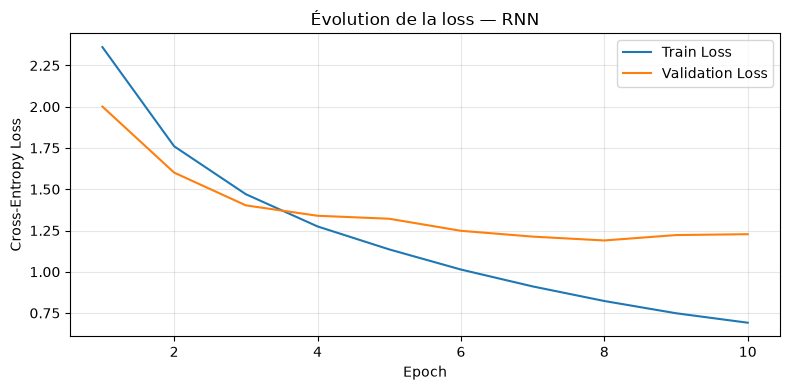

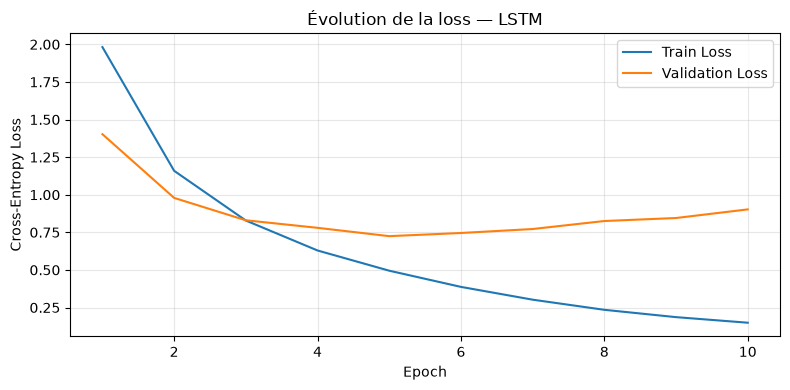

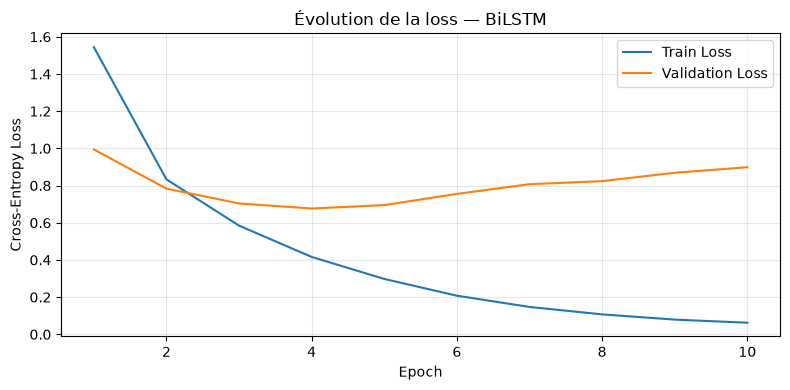

In [21]:

# Courbes d'apprentissage des trois modèles
# ------------------------------------------------------------
import matplotlib.pyplot as plt

historiques = {
    "RNN": historique_rnn,
    "LSTM": historique_lstm,
    "BiLSTM": historique_bilstm
}

for nom, historique in historiques.items():

    h = pd.DataFrame(historique)

    plt.figure(figsize=(8, 4))

    plt.plot(h["epoch"], h["train_loss"], label="Train Loss")
    plt.plot(h["epoch"], h["val_loss"], label="Validation Loss")

    plt.title(f"Évolution de la loss — {nom}")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-Entropy Loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


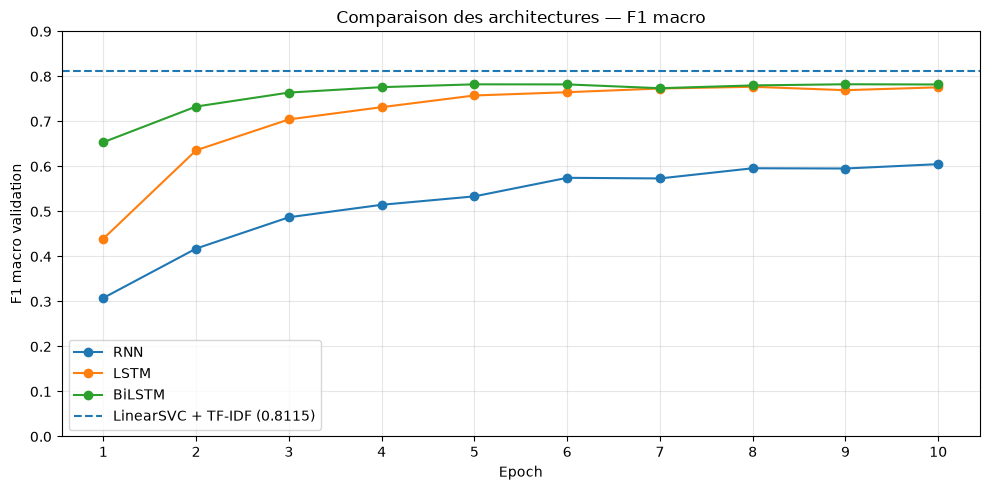

In [22]:

# Comparaison des F1 macro
# ------------------------------------------------------------
plt.figure(figsize=(10, 5))

for nom, historique in historiques.items():
    h = pd.DataFrame(historique)
    plt.plot(h["epoch"], h["f1_macro"], marker="o", label=nom)

# Référence Machine Learning
plt.axhline(y=0.8115,linestyle="--",label="LinearSVC + TF-IDF (0.8115)")

plt.title("Comparaison des architectures — F1 macro")
plt.xlabel("Epoch")
plt.ylabel("F1 macro validation")
plt.xticks(range(1, EPOCHS + 1))
plt.ylim(0, 0.9)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
